# Mini-Project 3 — Truncated normals in the pipeline problem (Problem 2)

**Variable data (Mini-Project 3):**

| Variable | Description | Distribution | Support | Mean | Std. deviation | COV |
|---|---|---|---|---|---|---|
| $F_y$ | Yield strength | Truncated normal | $[0,\infty)$ | 360 MPa | 36 MPa | 0.10 |
| $P$ | Internal pressure | Truncated normal | $[0,\infty)$ | 8 MPa | 1 MPa | 0.125 |
| $D$ | Pipe diameter | Deterministic | — | 600 mm | — | — |
| $t$ | Wall thickness | Deterministic | — | 10 mm | — | — |

Hoop stress $\sigma_h = \dfrac{PD}{2t}$ with $D=600$ mm and $t=10$ mm, so $\sigma_h = 30P$. Limit-state function:

$$g = F_y - 30P$$

- $F_y$ and $P$ are statistically independent.
- Failure occurs when $g \le 0$.

In Problem 2, the fact that the variables $F_y$ and $P$ cannot take negative values was ignored. That is, the PDF of the normal distribution was used from $-\infty$ to $\infty$, as shown in the following figure:

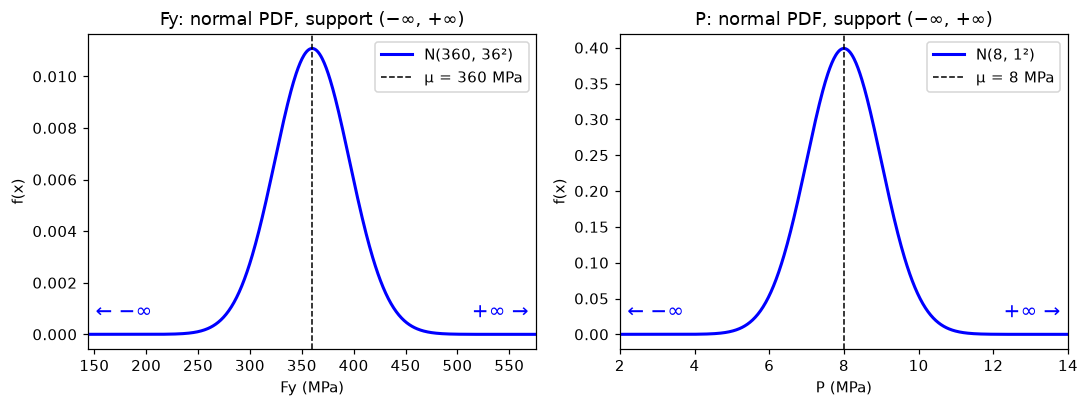

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, integrate

plt.rcParams["figure.dpi"] = 110

# Problem 2 data
D, t = 600.0, 10.0          # mm
k_hoop = D / (2 * t)        # sigma_h = k_hoop * P  -> 30
mu_Fy, sd_Fy = 360.0, 36.0  # MPa
mu_P, sd_P = 8.0, 1.0       # MPa

# Normal PDFs of Fy and P (Problem 2 model): support is (-inf, +inf)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (name, mu, sd) in zip(axes, [("Fy", mu_Fy, sd_Fy), ("P", mu_P, sd_P)]):
    dist = stats.norm(mu, sd)
    # Curve drawn past the axis limits so it runs off both edges
    x = np.linspace(mu - 7 * sd, mu + 7 * sd, 800)
    ax.plot(x, dist.pdf(x), "b-", lw=2, label=f"N({mu:g}, {sd:g}²)")
    ax.axvline(mu, color="k", ls="--", lw=1, label=f"μ = {mu:g} MPa")
    for sign, end, ha in [(-1, "← −∞", "left"), (1, "+∞ →", "right")]:
        ax.text(mu + sign * 5.8 * sd, 0.06 * dist.pdf(mu), end, color="b", fontsize=13, ha=ha)
    ax.set_xlim(mu - 6 * sd, mu + 6 * sd)
    ax.set_title(f"{name}: normal PDF, support (−∞, +∞)")
    ax.set_xlabel(f"{name} (MPa)"); ax.set_ylabel("f(x)")
    ax.legend()
plt.tight_layout(); plt.show()

When the distribution is truncated to the interval $[0,\infty)$, the probability that the normal distribution assigns to negative values must be removed, as shown in the following figure.

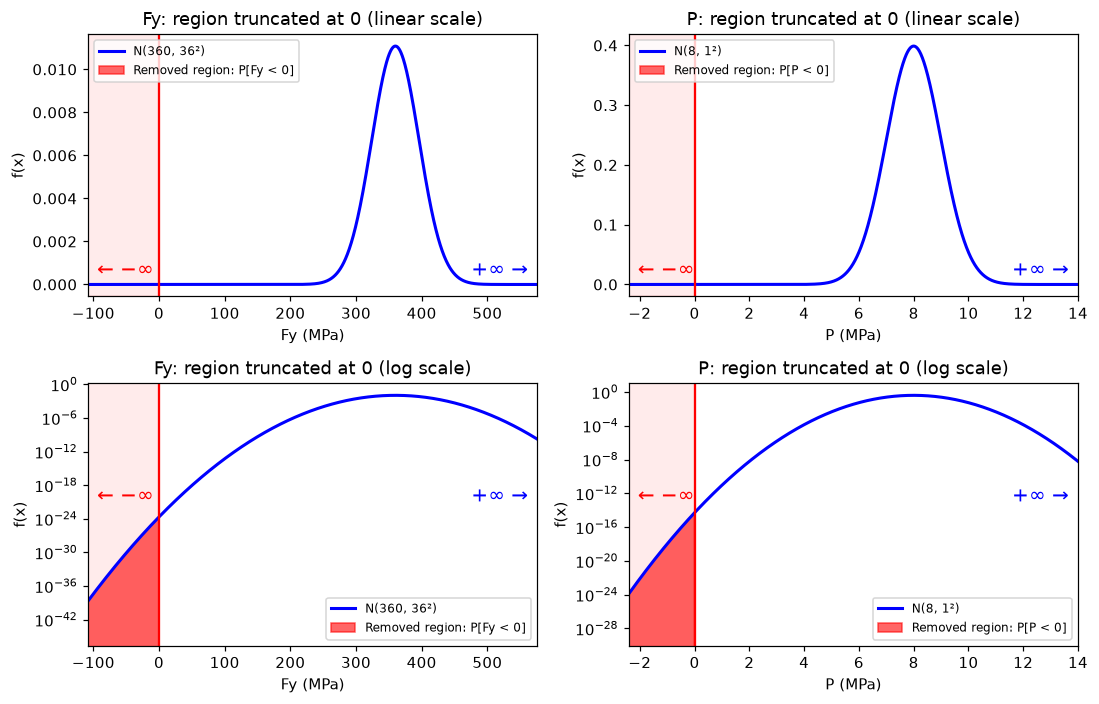

In [2]:
# Region removed by the truncation: x < 0 (from 0 down to -inf), shaded in red
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for col, (name, mu, sd) in enumerate([("Fy", mu_Fy, sd_Fy), ("P", mu_P, sd_P)]):
    dist = stats.norm(mu, sd)
    x_lo, x_hi = -0.3 * mu, mu + 6 * sd
    x = np.linspace(x_lo - sd, x_hi + sd, 2000)
    x_neg = x[x <= 0]
    for row, scale in enumerate(["linear", "log"]):
        ax = axes[row, col]
        ax.plot(x, dist.pdf(x), "b-", lw=2, label=f"N({mu:g}, {sd:g}²)")
        ax.axvspan(x_lo - sd, 0, color="red", alpha=0.08)
        ax.fill_between(x_neg, dist.pdf(x_neg), color="red", alpha=0.6,
                        label=f"Removed region: P[{name} < 0]")
        ax.axvline(0, color="red", lw=1.5)
        ax.set_yscale(scale)
        ax.set_xlim(x_lo, x_hi)
        # Infinity labels: y in axes fraction so they sit in empty space on both scales
        y_txt = 0.08 if scale == "linear" else 0.55
        ax.text(x_lo + 0.02 * (x_hi - x_lo), y_txt, "← −∞", color="red", fontsize=13,
                transform=ax.get_xaxis_transform())
        ax.text(x_hi - 0.02 * (x_hi - x_lo), y_txt, "+∞ →", color="b", fontsize=13, ha="right",
                transform=ax.get_xaxis_transform())
        ax.set_title(f"{name}: region truncated at 0 ({scale} scale)")
        ax.set_xlabel(f"{name} (MPa)"); ax.set_ylabel("f(x)")
        ax.legend(loc="upper left" if scale == "linear" else "lower right", fontsize=8)
plt.tight_layout(); plt.show()

The red area is the probability that the normal assigns to negative values, $P[X<0]$. This is exactly the part that is discarded when the distribution is truncated to $[0,\infty)$. For $X\sim N(\mu,\sigma^2)$:

$$P[X<0]=\Phi\!\left(\frac{0-\mu}{\sigma}\right)=\Phi\!\left(-\frac{\mu}{\sigma}\right)$$

Evaluating with the Problem 2 data:

| Variable | $\mu/\sigma$ | $P[X<0]$ |
|---|---|---|
| $F_y$ | $360/36 = 10$ | $\Phi(-10)\approx 7.6\times10^{-24}$ |
| $P$ | $8/1 = 8$ | $\Phi(-8)\approx 6.2\times10^{-16}$ |

## Part 1 — PDF of the truncated normals

For a normal variable $Y\sim N(\mu_0,\sigma_0^2)$, the PDF and the CDF of $Y$ are written as functions of the standardized variable $\dfrac{y-\mu_0}{\sigma_0}$:

$$
f_Y(y)=\frac{1}{\sigma_0}\,\phi\!\left(\frac{y-\mu_0}{\sigma_0}\right),\qquad
F_Y(y)=P(Y\le y)=\Phi\!\left(\frac{y-\mu_0}{\sigma_0}\right)
$$

Truncating at zero means keeping only the outcomes of $Y$ for which $Y\ge 0$.

If $X$ is the truncated variable of $Y$, $X$ will have the distribution of $Y$ conditioned on $Y\ge 0$:

$$F_X(x)=P(X\le x)=P(Y\le x\mid Y\ge 0)$$

Applying the definition of conditional probability:

$$
F_X(x)=\frac{P\big(\{Y\le x\}\cap\{Y\ge 0\}\big)}{P(Y\ge 0)}=\frac{P(0\le Y\le x)}{P(Y\ge 0)}
$$

The intersection $\{Y\le x\}\cap\{Y\ge 0\}$ occurs when both conditions hold at the same time, $Y\ge 0$ and $Y\le x$, that is, $0\le Y\le x$ (which requires $x\ge 0$).

Where:

$$P(0\le Y\le x)=F_Y(x)-F_Y(0)$$

and

$$
P(Y\ge 0)=1-P(Y\le 0)=1-F_Y(0)
$$

Therefore,

$$
F_X(x)=\frac{F_Y(x)-F_Y(0)}{1-F_Y(0)}
$$

To obtain the PDF, $F_X$ is differentiated with respect to $x$:

$$
f_X(x)=\frac{dF_X(x)}{dx}=\frac{1}{1-F_Y(0)}\left[\frac{dF_Y(x)}{dx}-\underbrace{\frac{dF_Y(0)}{dx}}_{=\,0}\right]=\frac{1}{1-F_Y(0)}\cdot\frac{dF_Y(x)}{dx}
$$

Since the derivative of the CDF is the PDF, $\dfrac{dF_Y(x)}{dx}=f_Y(x)$, then

$$
f_X(x)=\frac{f_Y(x)}{1-F_Y(0)},\qquad x\ge 0
$$

Finally, the known PDF, $f_Y(x)=\frac{1}{\sigma_0}\phi\!\left(\frac{x-\mu_0}{\sigma_0}\right)$, is substituted, and $F_Y(0)$ is evaluated directly with the mean and standard deviation of the original variable:

$$
F_Y(0)=\Phi\!\left(\frac{0-\mu_0}{\sigma_0}\right)=\Phi\!\left(-\frac{\mu_0}{\sigma_0}\right)
$$

$$
\boxed{f_X(x)=\frac{\dfrac{1}{\sigma_0}\,\phi\!\left(\dfrac{x-\mu_0}{\sigma_0}\right)}{1-\Phi\!\left(-\dfrac{\mu_0}{\sigma_0}\right)},\qquad x\ge 0}
$$

Substituting $\mu_0=360$ MPa and $\sigma_0=36$ MPa for $F_y$, and $\mu_0=8$ MPa and $\sigma_0=1$ MPa for $P$, the truncated PDFs are obtained:

$$
f_{F_y}(x)=\frac{\dfrac{1}{36}\,\phi\!\left(\dfrac{x-360}{36}\right)}{1-\Phi\!\left(-\dfrac{360}{36}\right)}
=\frac{\dfrac{1}{36\sqrt{2\pi}}\exp\!\left[-\dfrac{1}{2}\left(\dfrac{x-360}{36}\right)^2\right]}{1-\Phi(-10)},\qquad x\ge 0
$$

$$
f_{P}(x)=\frac{\dfrac{1}{1}\,\phi\!\left(\dfrac{x-8}{1}\right)}{1-\Phi\!\left(-\dfrac{8}{1}\right)}
=\frac{\dfrac{1}{\sqrt{2\pi}}\exp\!\left[-\dfrac{1}{2}\left(x-8\right)^2\right]}{1-\Phi(-8)},\qquad x\ge 0
$$

and both are equal to $0$ for $x<0$.

## Part 2 — Cornell index

To calculate the Cornell index with the truncated distributions, first the mean and standard deviation of each truncated variable are obtained, then those of the limit-state function and, finally, $\beta_C$.

Let $X$ be the variable $Y\sim N(\mu_0,\sigma_0^2)$ truncated to $[0,\infty)$. Its mean is the integral from $0$ to $\infty$ of $x$ times the truncated PDF from Part 1:

$$
\mu_X=E[X]=\int_0^\infty x\,f_X(x)\,dx=\mu_0+\sigma_0\,\frac{\phi\!\left(-\dfrac{\mu_0}{\sigma_0}\right)}{1-\Phi\!\left(-\dfrac{\mu_0}{\sigma_0}\right)}
$$

Its variance is the integral from $0$ to $\infty$ of $(x-\mu_X)^2$ times the truncated PDF, and its square root is the standard deviation:

$$
\sigma_X^2=\int_0^\infty (x-\mu_X)^2\,f_X(x)\,dx
$$

$$
\sigma_X=\sigma_0\sqrt{1-\frac{\mu_0}{\sigma_0}\,\frac{\phi\!\left(-\dfrac{\mu_0}{\sigma_0}\right)}{1-\Phi\!\left(-\dfrac{\mu_0}{\sigma_0}\right)}-\left[\frac{\phi\!\left(-\dfrac{\mu_0}{\sigma_0}\right)}{1-\Phi\!\left(-\dfrac{\mu_0}{\sigma_0}\right)}\right]^2}
$$

For $F_y$, with $\mu_0=360$ MPa and $\sigma_0=36$ MPa, we have $\dfrac{\mu_0}{\sigma_0}=10$, $\phi(-10)=7.7\times10^{-23}$ and $1-\Phi(-10)\approx 1$:

$$
\mu_{F_y}=360+36\,\frac{7.7\times10^{-23}}{1}=360+{\color{red}{\underbrace{2.8\times10^{-21}}_{\text{deviation}}}}\approx 360\ \text{MPa}
$$

$$
\sigma_{F_y}=36\sqrt{1-10\,\frac{7.7\times10^{-23}}{1}-\left(\frac{7.7\times10^{-23}}{1}\right)^2}=36{\color{red}{\underbrace{-1.4\times10^{-20}}_{\text{deviation}}}}\approx 36\ \text{MPa}
$$

For $P$, with $\mu_0=8$ MPa and $\sigma_0=1$ MPa, we have $\dfrac{\mu_0}{\sigma_0}=8$, $\phi(-8)=5.1\times10^{-15}$ and $1-\Phi(-8)\approx 1$:

$$
\mu_P=8+1\,\frac{5.1\times10^{-15}}{1}=8+{\color{red}{\underbrace{5.1\times10^{-15}}_{\text{deviation}}}}\approx 8\ \text{MPa}
$$

$$
\sigma_P=1\sqrt{1-8\,\frac{5.1\times10^{-15}}{1}-\left(\frac{5.1\times10^{-15}}{1}\right)^2}=1{\color{red}{\underbrace{-2.0\times10^{-14}}_{\text{deviation}}}}\approx 1\ \text{MPa}
$$

When truncating at $0$, the mean and standard deviation of the truncated variable are expected to deviate from those of the original variable. By removing the left tail, the mean shifts to the right and the dispersion decreases. However, in this case those deviations are of the order of $10^{-21}$ to $10^{-20}$ MPa for $F_y$ and $10^{-15}$ to $10^{-14}$ MPa for $P$, so they are practically negligible. This is because zero lies $10$ and $8$ standard deviations from the mean, respectively, and the probability that is removed is almost zero. Therefore, we can take $\mu_{F_y}=360$ MPa, $\sigma_{F_y}=36$ MPa, $\mu_P=8$ MPa and $\sigma_P=1$ MPa.

The limit-state function is $g=F_y-30P$. Since $g$ is a linear combination of $F_y$ and $P$, and these are independent, its mean and standard deviation are

$$
\mu_g=\mu_{F_y}-30\,\mu_P=360-30(8)=120\ \text{MPa}
$$

$$
\sigma_g=\sqrt{\sigma_{F_y}^2+30^2\,\sigma_P^2}=\sqrt{36^2+30^2(1)^2}=\sqrt{2196}=46.86\ \text{MPa}
$$

Finally, the Cornell reliability index is

$$
\beta_C=\frac{\mu_g}{\sigma_g}=\frac{120}{46.86}=2.561
$$

which is the same value obtained in Problem 2 with the non-truncated normals.

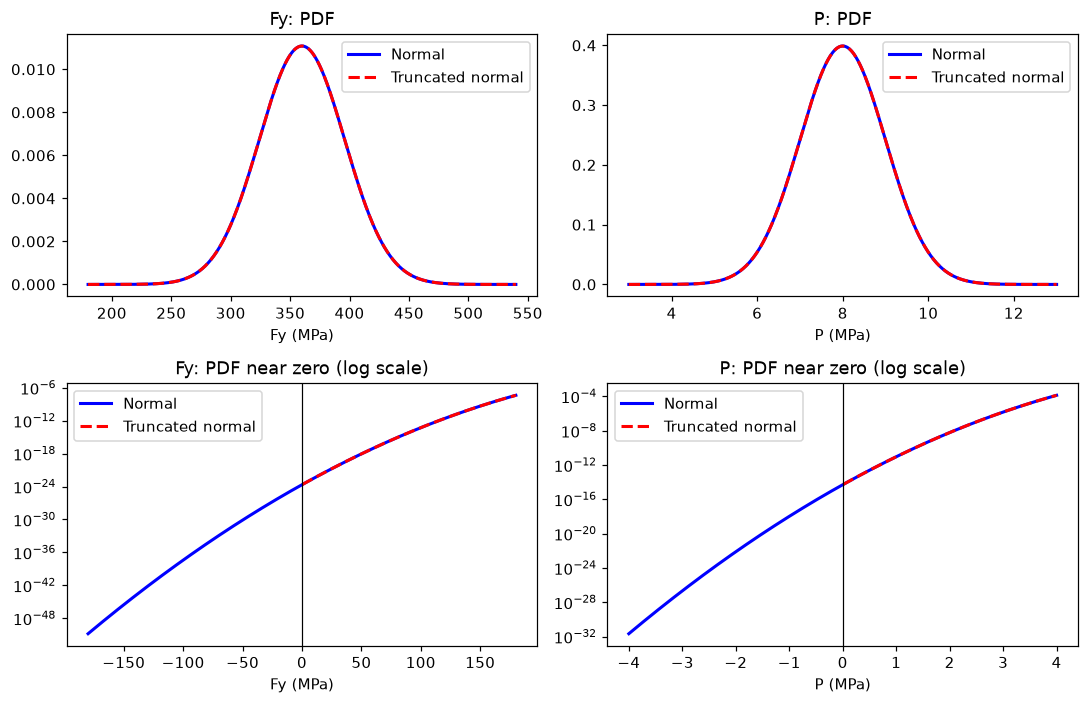

In [3]:
# Normal (Problem 2) and truncated normal on [0, inf) with mu0 = mu, sigma0 = sigma
Fy_N, P_N = stats.norm(mu_Fy, sd_Fy), stats.norm(mu_P, sd_P)
Fy_T = stats.truncnorm(-mu_Fy / sd_Fy, np.inf, loc=mu_Fy, scale=sd_Fy)
P_T = stats.truncnorm(-mu_P / sd_P, np.inf, loc=mu_P, scale=sd_P)

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for col, (name, N, T, mu, sd, unit) in enumerate([("Fy", Fy_N, Fy_T, mu_Fy, sd_Fy, "MPa"),
                                                   ("P", P_N, P_T, mu_P, sd_P, "MPa")]):
    x = np.linspace(mu - 5 * sd, mu + 5 * sd, 600)
    ax = axes[0, col]
    ax.plot(x, N.pdf(x), "b-", lw=2, label="Normal")
    ax.plot(x, T.pdf(x), "r--", lw=2, label="Truncated normal")
    ax.set_title(f"{name}: PDF"); ax.set_xlabel(f"{name} ({unit})"); ax.legend()
    # Near zero, log scale: where the two models differ
    xz = np.linspace(-0.5 * mu, 0.5 * mu, 600)
    ax = axes[1, col]
    ax.semilogy(xz, N.pdf(xz), "b-", lw=2, label="Normal")
    ax.semilogy(xz[xz >= 0], T.pdf(xz[xz >= 0]), "r--", lw=2, label="Truncated normal")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{name}: PDF near zero (log scale)"); ax.set_xlabel(f"{name} ({unit})"); ax.legend()
plt.tight_layout(); plt.show()

At the top, the two curves are indistinguishable. At the bottom, on a logarithmic scale, the only difference can be seen: the normal continues for $x<0$ with densities of the order of $10^{-24}$ for $F_y$ and $10^{-15}$ for $P$ at $x=0$, and smaller further left, while the truncated one is zero.

## Part 3 — Comparison and discussion

For this application, it could be stated that the normal distribution assumption does not introduce significant inaccuracies. This is mainly due to the low coefficient of variation of the variables in the problem (0.10 for $F_y$ and 0.125 for $P$). With these values, the probability of having negative values is very low: less than $10^{-23}$ for $F_y$ and less than $10^{-15}$ for $P$. In applications with variables that assign significant probabilities to negative values, the normal distribution assumption could indeed introduce a loss of accuracy in the calculations.

To illustrate this effect, a hypothetical case is considered in which $F_y$ has a high coefficient of variation of 0.5, that is, $\mu_0=360$ MPa and $\sigma_0=180$ MPa, while $P$ remains the same as in Problem 2. This value is not realistic for steel and is used only to illustrate the effect. In this case, the normal assigns a probability of $\Phi(-2)=0.023$ to negative values.

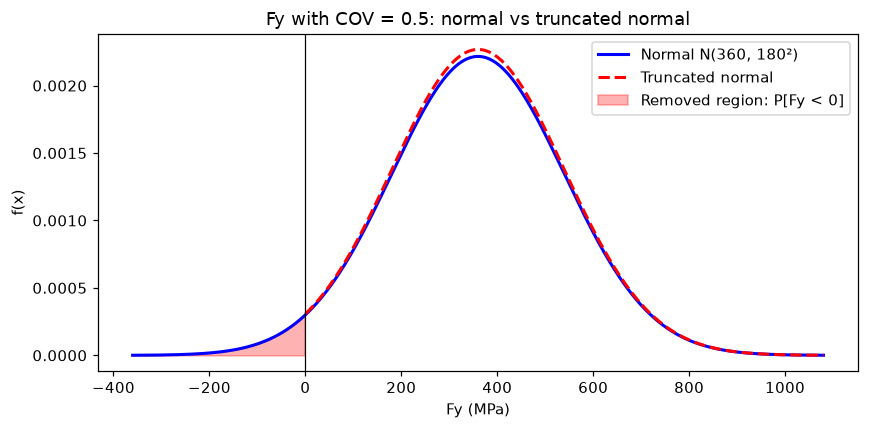

In [4]:
# Illustrative case: Fy with a high COV (0.5); P unchanged
mu_Fy_ex, sd_Fy_ex = 360.0, 180.0  # MPa
Fy_N_ex = stats.norm(mu_Fy_ex, sd_Fy_ex)
Fy_T_ex = stats.truncnorm(-mu_Fy_ex / sd_Fy_ex, np.inf, loc=mu_Fy_ex, scale=sd_Fy_ex)

x = np.linspace(mu_Fy_ex - 4 * sd_Fy_ex, mu_Fy_ex + 4 * sd_Fy_ex, 800)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, Fy_N_ex.pdf(x), "b-", lw=2, label=f"Normal N({mu_Fy_ex:g}, {sd_Fy_ex:g}²)")
ax.plot(x[x >= 0], Fy_T_ex.pdf(x[x >= 0]), "r--", lw=2, label="Truncated normal")
ax.fill_between(x[x <= 0], Fy_N_ex.pdf(x[x <= 0]), color="red", alpha=0.3, label="Removed region: P[Fy < 0]")
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Fy with COV = 0.5: normal vs truncated normal")
ax.set_xlabel("Fy (MPa)"); ax.set_ylabel("f(x)"); ax.legend()
plt.tight_layout(); plt.show()

Using the formulas from Part 2, for the truncated $F_y$ with $\mu_0=360$ MPa and $\sigma_0=180$ MPa, we have $\dfrac{\mu_0}{\sigma_0}=2$, $\phi(-2)=0.0540$ and $1-\Phi(-2)=0.9772$:

$$
\mu_{F_y}=360+180\,\frac{0.0540}{0.9772}=360+{\color{red}{\underbrace{9.94}_{\text{deviation}}}}=369.94\ \text{MPa}
$$

$$
\sigma_{F_y}=180\sqrt{1-2\,\frac{0.0540}{0.9772}-\left(\frac{0.0540}{0.9772}\right)^2}=180\sqrt{0.8865}=180{\color{red}{\underbrace{-10.53}_{\text{deviation}}}}=169.47\ \text{MPa}
$$

For $P$, $\mu_P=8$ MPa and $\sigma_P=1$ MPa are kept, as in Part 2.

With the normal distribution, the limit-state function $g=F_y-30P$ has

$$
\mu_g=360-30(8)=120\ \text{MPa},\qquad \sigma_g=\sqrt{180^2+30^2(1)^2}=\sqrt{33300}=182.48\ \text{MPa}
$$

$$
\beta_C=\frac{120}{182.48}=0.658
$$

With the truncated distribution:

$$
\mu_g=369.94-30(8)=129.94\ \text{MPa},\qquad \sigma_g=\sqrt{169.47^2+30^2(1)^2}=\sqrt{29620}=172.11\ \text{MPa}
$$

$$
\beta_C=\frac{129.94}{172.11}=0.755
$$

In this case, the Cornell index with the truncated distribution is 14.8% higher than with the normal. By removing the negative values of the resistance, the mean of $F_y$ increases and its dispersion decreases, so the calculated reliability increases. That is, when the variable has a significant probability of negative values, the normal distribution assumption does introduce an important difference in the results.

**Note:** This mini-project was developed using Claude Code for the organization of the notebook and also for the generation of the code for the plots that illustrate the concepts.